# MLP KA1 – Flight Ticket Price Prediction

**Task:** predict `price` of a flight ticket (regression). **Metric:** R² score on the hidden test set.

**Constraint:** only classical scikit-learn models are used (no deep learning).

**Notebook outline**

1. Setup & data loading
2. Data types of each column
3. Descriptive statistics
4. Duplicates – identify & handle
5. Missing values – identify & handle
6. Outliers – identify & decide
7. Visualizations & insights
8. Feature engineering, scaling & encoding
9. Model building (9 models)
10. Hyperparameter tuning (4 models)
11. Model comparison on the validation set
12. Final model & submission

## 1. Setup & data loading

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

RANDOM_STATE = 42
N_JOBS = -1   # use all CPU cores

In [2]:
# Works both on Kaggle (/kaggle/input/...) and locally (files next to the notebook)
if os.path.exists('train.csv'):
    DATA_DIR = '.'
else:
    DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/train.csv', recursive=True)[0])

train_raw = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test_raw  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
sample_sub = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))

print('Train shape:', train_raw.shape)
print('Test shape :', test_raw.shape)
train_raw.head()

Train shape: (40000, 12)
Test shape : (10000, 11)


,id,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,NaN,40.0,64173
1,1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357
2,2,SpiceJet,SG-8107,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251
3,3,NaN,0.00E+00,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0,1776
4,4,Air_India,AI-569,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0,3584


## 2. Data types of the columns

In [3]:
train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           40000 non-null  int64  
 1   airline      35387 non-null  str    
 2   flight       40000 non-null  str    
 3   source       40000 non-null  str    
 4   departure    35208 non-null  str    
 5   stops        37681 non-null  str    
 6   arrival      40000 non-null  str    
 7   destination  40000 non-null  str    
 8   class        40000 non-null  str    
 9   duration     36987 non-null  float64
 10  days_left    35562 non-null  float64
 11  price        40000 non-null  int64  
dtypes: float64(2), int64(2), str(8)
memory usage: 3.7 MB


In [ ]:
feature_type = {
    'id':          'Identifier (not a feature – dropped)',
    'airline':     'Categorical – nominal (6 airlines)',
    'flight':      'Categorical – nominal, high cardinality (flight code)',
    'source':      'Categorical – nominal (6 cities)',
    'departure':   'Categorical – ordinal (time-of-day bucket)',
    'stops':       'Categorical – ordinal (zero < one < two_or_more)',
    'arrival':     'Categorical – ordinal (time-of-day bucket)',
    'destination': 'Categorical – nominal (6 cities)',
    'class':       'Categorical – binary (Economy / Business)',
    'duration':    'Numerical – continuous (hours)',
    'days_left':   'Numerical – discrete (integer days 1–49, stored as float because of NaNs)',
    'price':       'Numerical – continuous  ← TARGET',
}
dtype_table = pd.DataFrame({
    'pandas dtype': train_raw.dtypes.astype(str),
    'unique values': train_raw.nunique(),
    'example': train_raw.iloc[0],
    'feature type': pd.Series(feature_type),
})
dtype_table

,pandas dtype,unique values,example,feature type
id,int64,40000,0,Identifier (not a feature – dropped)
airline,str,6,Vistara,Categorical – nominal (6 airlines)
flight,str,869,UK-930,"Categorical – nominal, high cardinality (fligh..."
source,str,6,Mumbai,Categorical – nominal (6 cities)
departure,str,6,Early_Morning,Categorical – ordinal (time-of-day bucket)
stops,str,3,one,Categorical – ordinal (zero < one < two_or_more)
arrival,str,6,Night,Categorical – ordinal (time-of-day bucket)
destination,str,6,Chennai,Categorical – nominal (6 cities)
class,str,2,Business,Categorical – binary (Economy / Business)
duration,float64,416,NaN,Numerical – continuous (hours)


**Data types**

* **Numerical (3):** `duration` (continuous, float), `days_left` (discrete integer days, read as float only because it has NaNs), `price` (target, integer rupees).
* **Categorical (8):** `airline`, `flight`, `source`, `destination` (nominal), `departure`, `arrival`, `stops` (ordinal), `class` (binary).
* `id` is only a row identifier and is not used as a feature.
* `flight` is read as a string. Some codes were corrupted by a spreadsheet program (see Section 5).

## 3. Descriptive statistics

In [5]:
num_cols_raw = ['duration', 'days_left', 'price']
stats = train_raw[num_cols_raw].describe().T
stats.insert(stats.columns.get_loc('mean') + 1, 'median', train_raw[num_cols_raw].median())
stats['skew'] = train_raw[num_cols_raw].skew()
stats.round(2)

,count,mean,median,std,min,25%,50%,75%,max,skew
duration,36987.0,12.00,11.08,7.11,0.83,6.67,11.08,15.92,47.08,0.61
days_left,35562.0,26.20,26.00,13.47,1.00,15.00,26.00,38.00,49.00,-0.05
price,40000.0,20801.49,7353.00,22729.15,1105.00,4687.00,7353.00,42521.00,114704.00,1.06


In [6]:
# Price statistics split by class – the single most important driver
train_raw.groupby('class')['price'].agg(['count', 'min', 'max', 'mean', 'median', 'std']).round(1)

,count,min,max,mean,median,std
class,,,,,,
Business,12464,12000,114704,52499.1,53209.0,12989.4
Economy,27536,1105,37646,6453.8,5660.0,3664.4


In [7]:
train_raw.describe(exclude='number').T

,count,unique,top,freq
airline,35387,6,Vistara,15063
flight,40000,869,0.00E+00,5240
source,40000,6,Delhi,8189
departure,35208,6,Morning,8302
stops,37681,3,one,31439
arrival,40000,6,Night,12348
destination,40000,6,Mumbai,7821
class,40000,2,Economy,27536


**Observations**

| column | min | max | mean | median |
|---|---|---|---|---|
| duration (h) | 0.83 | 47.08 | 12.00 | 11.08 |
| days_left | 1 | 49 | 26.2 | 26 |
| price (₹) | 1,105 | 114,704 | 20,801 | 7,353 |

* `price` is strongly right-skewed (mean ≫ median). The cause is the **two seat classes**: Economy has a median of ≈ ₹5.7k and Business a median of ≈ ₹53k.
* `duration` is a little right-skewed: a few itineraries with long layovers go up to 47 h.
* `days_left` is close to uniform over 1–49.
* Vistara is the most frequent airline and `one` stop is by far the most common value.

## 4. Duplicates – identify & handle

In [8]:
feat_cols = [c for c in train_raw.columns if c not in ('id', 'price')]

exact_dups = train_raw.drop(columns='id').duplicated().sum()
feature_dups = train_raw.duplicated(subset=feat_cols).sum()
print(f'Exact duplicate rows (all columns except id): {exact_dups}')
print(f'Rows with identical features (price may differ): {feature_dups}')
print(f'Duplicate ids: {train_raw["id"].duplicated().sum()}')

Exact duplicate rows (all columns except id): 250
Rows with identical features (price may differ): 488
Duplicate ids: 0


In [9]:
train_dedup = train_raw.drop_duplicates(subset=feat_cols + ['price']).reset_index(drop=True)
print('Train shape after dropping exact duplicates:', train_dedup.shape)

Train shape after dropping exact duplicates: (39750, 12)


**Duplicates**

* 250 rows are **exact duplicates** (every column except `id` is the same). They add no information and would give those records extra weight, so they are **dropped**.
* About 240 more rows share the same features but have a *different* price. These are kept: the same flight and booking window can really sell at different fares, and these rows tell the model how noisy the target is.

## 5. Missing values – identify & handle

In [10]:
miss = pd.DataFrame({
    'train_missing': train_dedup.isna().sum(),
    'train_%': (train_dedup.isna().mean() * 100).round(2),
    'test_missing': test_raw.isna().sum().reindex(train_dedup.columns),
    'test_%': (test_raw.isna().mean() * 100).round(2).reindex(train_dedup.columns),
})
miss[miss.train_missing.gt(0) | miss.test_missing.gt(0)]

,train_missing,train_%,test_missing,test_%
airline,4609,11.59,548.0,5.48
departure,4788,12.05,920.0,9.20
stops,2319,5.83,651.0,6.51
duration,3005,7.56,582.0,5.82
days_left,4195,10.55,696.0,6.96


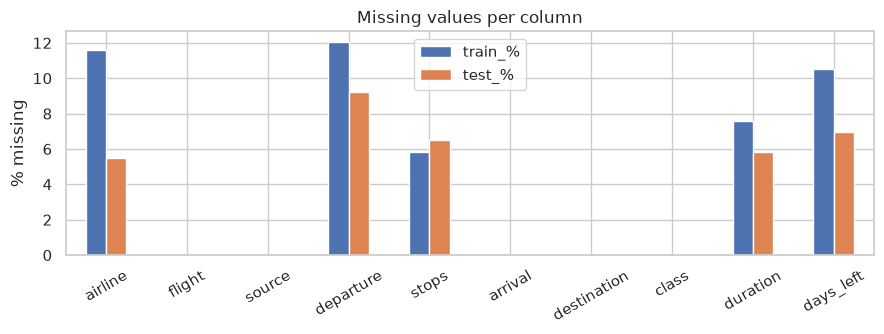

In [11]:
plt.figure(figsize=(9, 3.5))
miss[['train_%', 'test_%']].drop(index=['id', 'price']).plot.bar(ax=plt.gca())
plt.ylabel('% missing'); plt.title('Missing values per column'); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

**Hidden missing values in `flight`.** The flight codes look complete, but every IndiGo code (`6E-xxx`) was turned into a number by a spreadsheet program:

* `6E-269` was read as 6×10⁻²⁶⁹ and stored as `6.00E-269`. This one **can be recovered** to `6E-269`.
* `0.00E+00` / `0.00E-02` underflowed to zero, so the original code is **lost**.

In [12]:
mangled = train_dedup['flight'][train_dedup['flight'].str.contains('E', regex=False)]
print('Spreadsheet-mangled flight codes in train:', len(mangled))
print(mangled.value_counts().head(8))
print()
print('Airline of rows with mangled codes:')
print(train_dedup.loc[mangled.index, 'airline'].value_counts(dropna=False))

Spreadsheet-mangled flight codes in train: 5905
flight
0.00E+00     5224
6.00E-269      40
6.00E-179      34
0.00E-02       30
6.00E-157      27
6.00E-139      26
6.00E-156      22
6.00E-135      21
Name: count, dtype: int64

Airline of rows with mangled codes:
airline
Indigo    5219
NaN        686
Name: count, dtype: int64


**Imputation strategy.** The fill values come only from the *features* of train + test combined. The target is never used, so `price` cannot leak into the features.

| column | strategy | reason |
|---|---|---|
| `flight` | `6.00E-xxx` → `6E-xxx`; `0.00E…` → `6E-UNKNOWN` | undo the spreadsheet corruption |
| `airline` | read from the flight-code prefix (`UK`→Vistara, `AI`→Air India, `6E`→Indigo, …) | the prefix identifies the airline exactly, so these fills are correct, not estimates |
| `stops` | most common value for the same flight on the same route, otherwise for the same airline + route, otherwise the overall mode | a given flight on a given route almost always has the same number of stops |
| `departure` | most common value for the same flight, otherwise the overall mode | a flight number leaves at a fixed time of day |
| `duration` | median for the same flight + route + stops, otherwise route + stops, otherwise the overall median | duration is set by the itinerary |
| `days_left` | overall median | depends only on when the booking was made, so no other column predicts it |

In [13]:
PREFIX_TO_AIRLINE = {'UK': 'Vistara', 'AI': 'Air_India', '6E': 'Indigo',
                     'G8': 'GO_FIRST', 'I5': 'AirAsia', 'SG': 'SpiceJet'}

def fix_flight(code):
    if code.startswith('6.00E-'):     # '6E-269' was read as 6e-269
        return '6E-' + code[len('6.00E-'):]
    if code.startswith('0.00E'):      # underflowed to 0 -> original code is lost
        return '6E-UNKNOWN'
    return code

def fill_by_groups(df, col, group_levels, how):
    # Fill NaNs in `col` using the mode/median of progressively coarser groups, then a global value.
    for keys in group_levels:
        if how == 'mode':
            fill = df.groupby(keys)[col].transform(
                lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
        else:
            fill = df.groupby(keys)[col].transform('median')
        df[col] = df[col].fillna(fill)
    df[col] = df[col].fillna(df[col].mode()[0] if how == 'mode' else df[col].median())
    return df

full = pd.concat([train_dedup.assign(_set='train'), test_raw.assign(_set='test')], ignore_index=True)

full['flight']  = full['flight'].map(fix_flight)
full['airline'] = full['airline'].fillna(full['flight'].str.split('-').str[0].map(PREFIX_TO_AIRLINE))
full = fill_by_groups(full, 'stops', [['flight', 'source', 'destination'],
                                      ['airline', 'source', 'destination']], 'mode')
full = fill_by_groups(full, 'departure', [['flight']], 'mode')
full = fill_by_groups(full, 'duration', [['flight', 'source', 'destination', 'stops'],
                                         ['source', 'destination', 'stops']], 'median')
full = fill_by_groups(full, 'days_left', [], 'median')

assert set(full['flight'].str.split('-').str[0]) <= set(PREFIX_TO_AIRLINE)

train = full[full._set == 'train'].drop(columns='_set').reset_index(drop=True)
test  = full[full._set == 'test'].drop(columns=['_set', 'price']).reset_index(drop=True)

print('Missing values after imputation – train:', int(train.drop(columns='price').isna().sum().sum()),
      '| test:', int(test.isna().sum().sum()))

Missing values after imputation – train: 0 | test: 0


## 6. Outliers – identify & decide

In [14]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (s < lo) | (s > hi), lo, hi

rows = []
for c in ['duration', 'days_left', 'price']:
    mask, lo, hi = iqr_outliers(train[c])
    rows.append({'column': c, 'lower fence': round(lo, 2), 'upper fence': round(hi, 2), 'n_outliers': int(mask.sum())})
for cls, g in train.groupby('class'):
    mask, lo, hi = iqr_outliers(g['price'])
    rows.append({'column': f'price | class={cls}', 'lower fence': round(lo, 2), 'upper fence': round(hi, 2), 'n_outliers': int(mask.sum())})
pd.DataFrame(rows)

,column,lower fence,upper fence,n_outliers
0,duration,-7.21,29.8,244
1,days_left,-14.00,66.0,0
2,price,-51968.00,99112.0,14
3,price | class=Business,22415.00,83135.0,515
4,price | class=Economy,-1085.00,12771.0,1929


Class of the overall price outliers: {'Business': 14}
Stops of the duration outliers     : {'one': 159, 'two_or_more': 85}


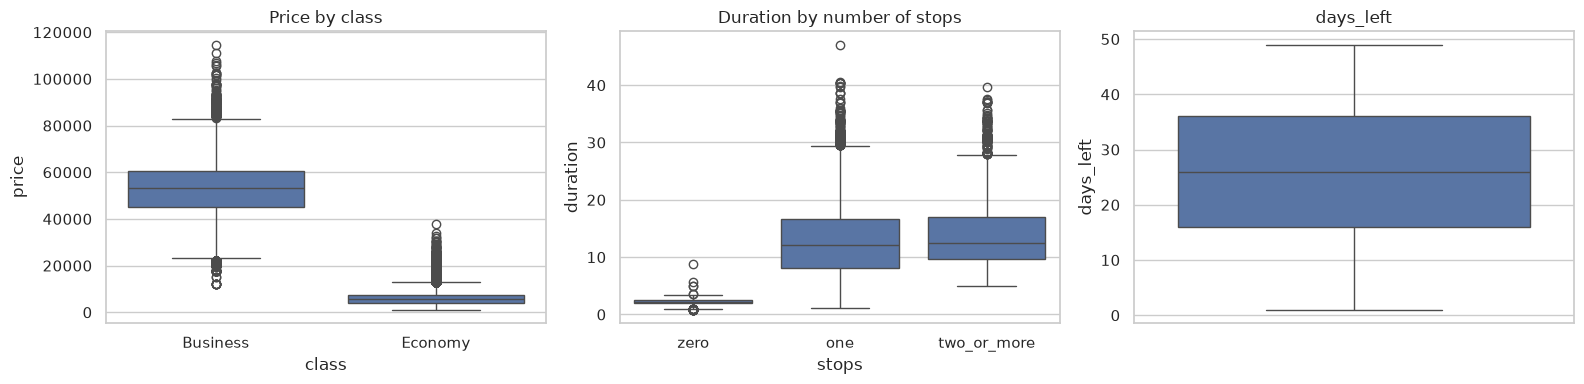

In [15]:
price_out, _, _ = iqr_outliers(train['price'])
print('Class of the overall price outliers:', train.loc[price_out, 'class'].value_counts().to_dict())
dur_out, _, _ = iqr_outliers(train['duration'])
print('Stops of the duration outliers     :', train.loc[dur_out, 'stops'].value_counts().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=train, x='class', y='price', ax=axes[0]); axes[0].set_title('Price by class')
sns.boxplot(data=train, x='stops', y='duration', order=['zero', 'one', 'two_or_more'], ax=axes[1])
axes[1].set_title('Duration by number of stops')
sns.boxplot(data=train, y='days_left', ax=axes[2]); axes[2].set_title('days_left')
plt.tight_layout(); plt.show()

**Outlier decision: keep all rows.**

* **price:** the few overall IQR outliers are all Business fares, and they are real premium fares, not errors. Within each class the IQR rule flags more points (expensive last-minute Economy tickets and top Business fares). These are just the upper tail of the fare distribution. The test set comes from the same distribution, and R² penalizes large errors on expensive tickets heavily, so the model needs to learn them.
* **duration:** long durations (> ~31 h) all belong to one-stop or multi-stop itineraries with long layovers. That is plausible, and they line up with the `stops` column.
* **days_left:** no outliers (range 1–49).
* No row is dropped. The tree models are not sensitive to extreme feature values, and the linear models get standardized inputs.

## 7. Visualizations & insights

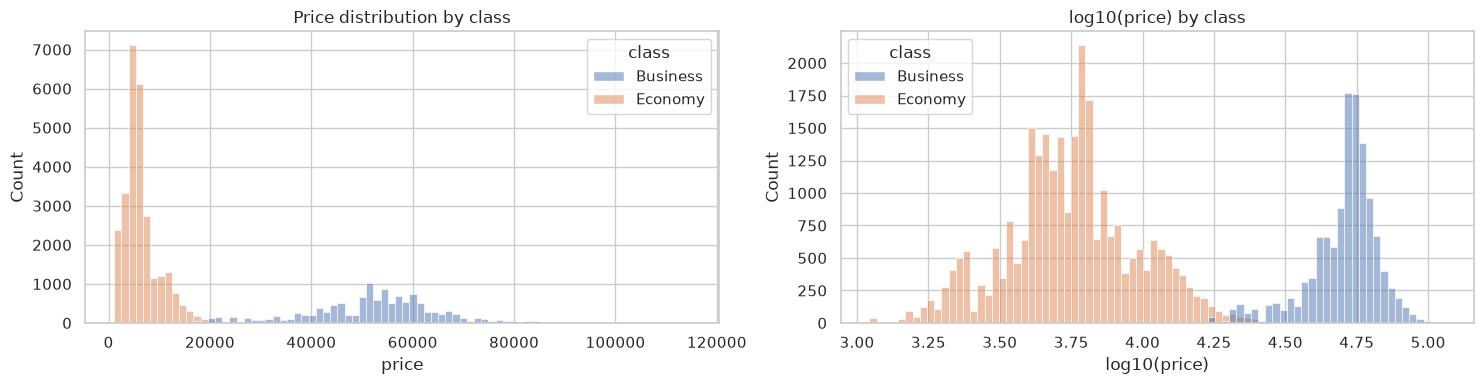

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(data=train, x='price', hue='class', bins=80, ax=axes[0])
axes[0].set_title('Price distribution by class')
sns.histplot(data=train, x=np.log10(train['price']), hue=train['class'], bins=80, ax=axes[1])
axes[1].set_xlabel('log10(price)'); axes[1].set_title('log10(price) by class')
plt.tight_layout(); plt.show()

**Insight 1 – price is bimodal because of seat class.** Economy and Business form two separate groups, about 8× apart (medians ≈ ₹5.7k vs ≈ ₹53k). `class` alone explains most of the variance in price, so every model must capture it, and it should be combined with other features (e.g. `airline × class`).

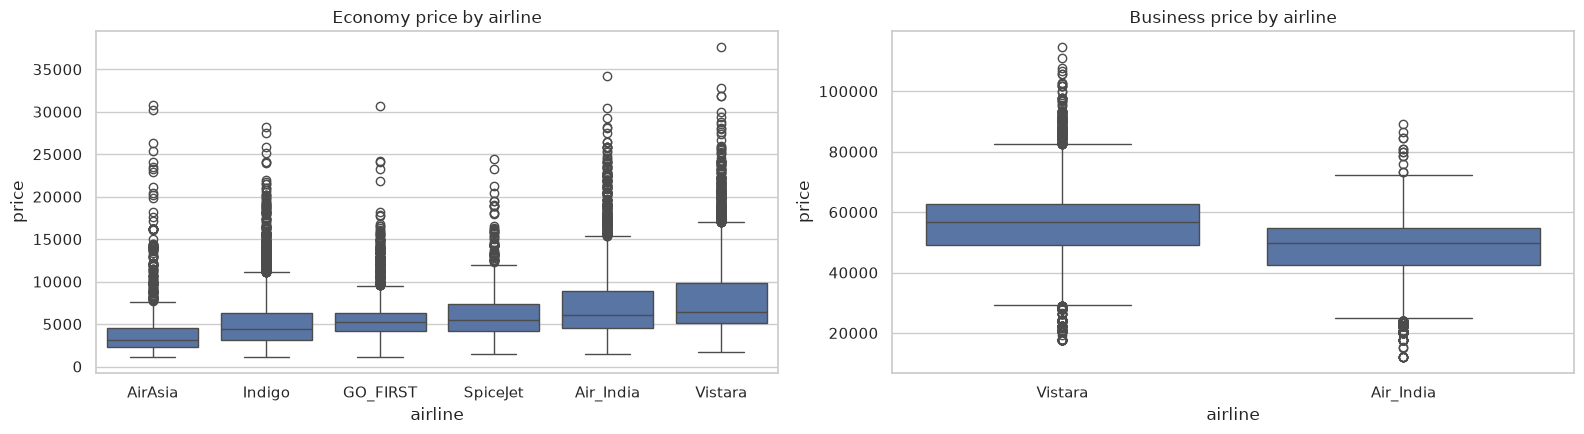

class      Business  Economy
airline                     
AirAsia           0     2190
Air_India      4266     6086
GO_FIRST          0     3153
Indigo            0     5905
SpiceJet          0     1243
Vistara        8065     8842


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
order = train.groupby('airline')['price'].median().sort_values().index
sns.boxplot(data=train[train['class'] == 'Economy'], x='airline', y='price', order=order, ax=axes[0])
axes[0].set_title('Economy price by airline')
sns.boxplot(data=train[train['class'] == 'Business'], x='airline', y='price', ax=axes[1])
axes[1].set_title('Business price by airline')
plt.tight_layout(); plt.show()
print(pd.crosstab(train['airline'], train['class']))

**Insight 2 – the airline matters, and only two airlines sell Business.** Only **Vistara** and **Air India** have Business-class seats. In Economy, the low-cost carriers (AirAsia, Indigo, GO_FIRST, SpiceJet) are clearly cheaper than the full-service Vistara and Air India.

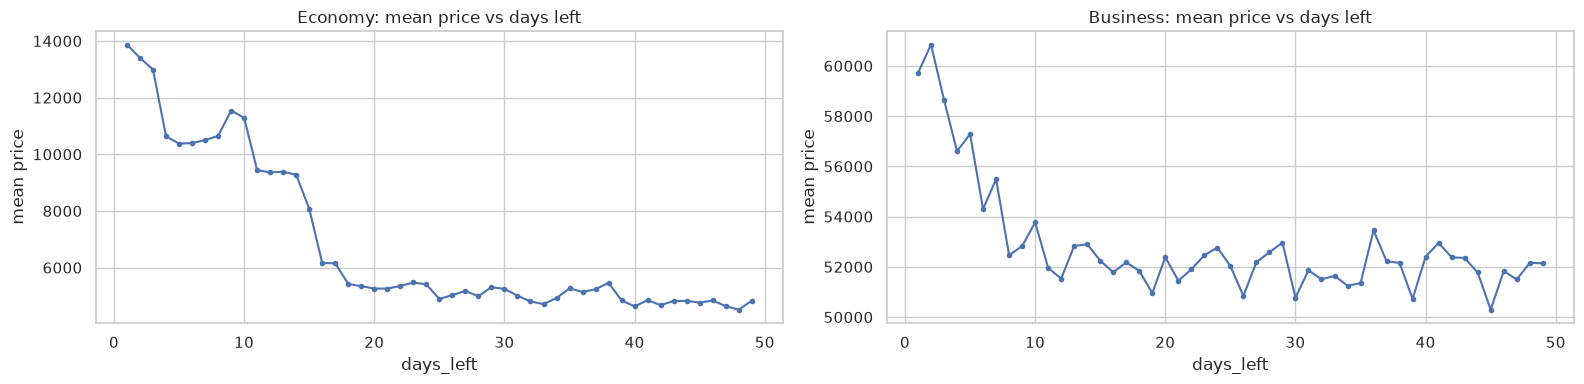

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
raw_dl = train_dedup.dropna(subset=['days_left'])   # use non-imputed values for this plot
for ax, cls in zip(axes, ['Economy', 'Business']):
    s = raw_dl[raw_dl['class'] == cls].groupby('days_left')['price'].mean()
    ax.plot(s.index, s.values, marker='o', ms=3)
    ax.set_title(f'{cls}: mean price vs days left'); ax.set_xlabel('days_left'); ax.set_ylabel('mean price')
plt.tight_layout(); plt.show()

**Insight 3 – prices go up sharply as the flight gets closer.** Economy tickets bought within ~2 weeks of departure average **₹10k–14k**, while tickets bought more than 3 weeks ahead average only **≈ ₹5k**: a 2–3× jump, with an almost flat curve beyond ~3 weeks. Business fares rise much less (≈ ₹52k → ₹60k). The relationship is **non-linear** (a step and a plateau rather than a straight line) and differs by class, so tree-based models should beat plain linear ones.

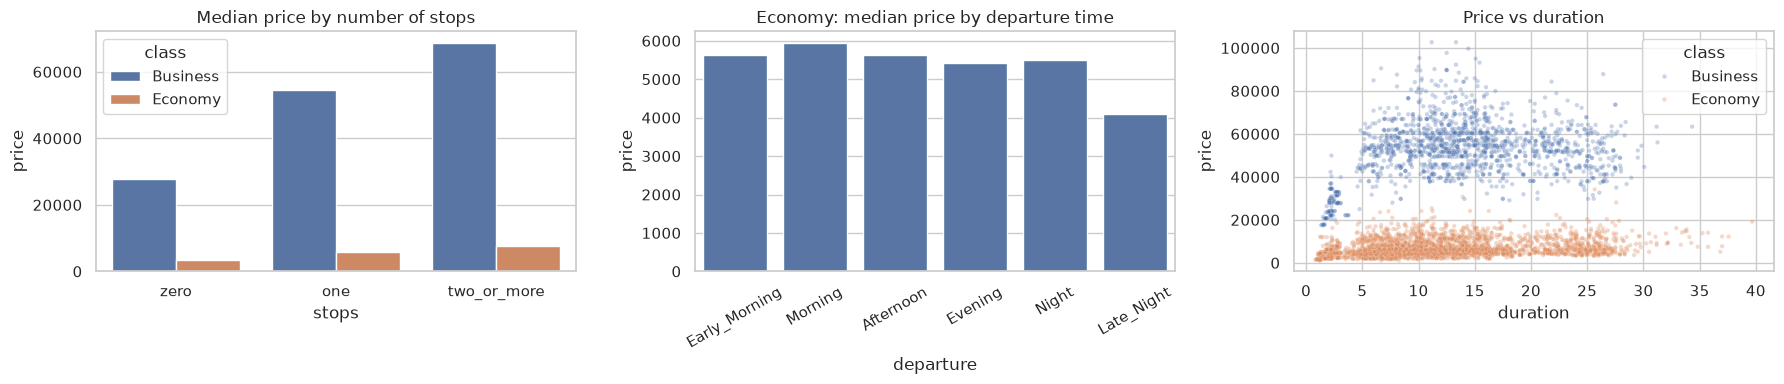

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.barplot(data=train, x='stops', y='price', hue='class', order=['zero', 'one', 'two_or_more'],
            estimator='median', errorbar=None, ax=axes[0])
axes[0].set_title('Median price by number of stops')
tod = ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night']
sns.barplot(data=train[train['class'] == 'Economy'], x='departure', y='price', order=tod,
            estimator='median', errorbar=None, ax=axes[1])
axes[1].set_title('Economy: median price by departure time'); axes[1].tick_params(axis='x', rotation=30)
sns.scatterplot(data=train.sample(5000, random_state=RANDOM_STATE), x='duration', y='price',
                hue='class', alpha=0.3, s=10, ax=axes[2])
axes[2].set_title('Price vs duration')
plt.tight_layout(); plt.show()

**Insight 4 – stops and time of day.** Price rises with the number of stops in both classes (Economy medians: zero ≈ ₹3.4k, one ≈ ₹5.9k, two or more ≈ ₹7.8k). Connecting itineraries are mostly flown by the full-service carriers and cover longer distances. **Late-night** departures are clearly the cheapest (Economy ≈ ₹4.1k vs ₹5.3k–6.0k for the other slots). Price rises slowly with duration, mainly through the number of stops.

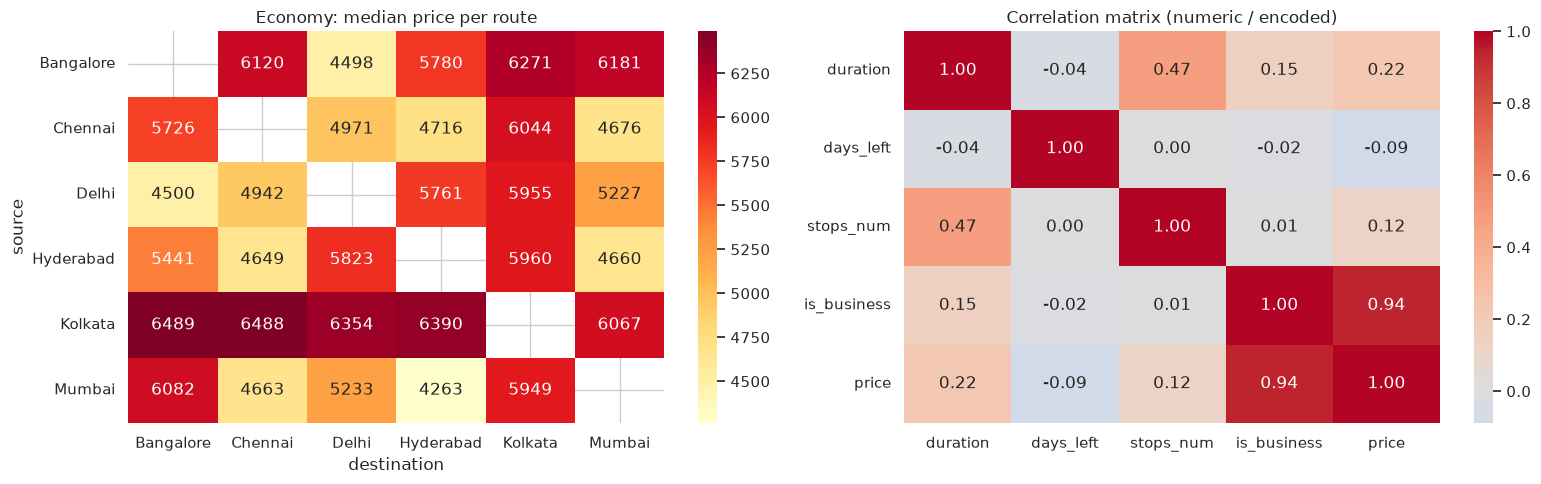

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pivot = train[train['class'] == 'Economy'].pivot_table(index='source', columns='destination',
                                                         values='price', aggfunc='median')
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', ax=axes[0])
axes[0].set_title('Economy: median price per route')

corr_df = train.assign(stops_num=train['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2}),
                       is_business=(train['class'] == 'Business').astype(int))
sns.heatmap(corr_df[['duration', 'days_left', 'stops_num', 'is_business', 'price']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Correlation matrix (numeric / encoded)')
plt.tight_layout(); plt.show()

**Insight 5 – route and correlations.** Median Economy prices differ by route. Every flight **departing from Kolkata** is expensive (≈ ₹6.0k–6.5k), while Mumbai→Hyderabad (≈ ₹4.3k) and Delhi↔Bangalore (≈ ₹4.5k) are the cheapest. Price also depends on direction (e.g. Bangalore→Kolkata ≠ Kolkata→Bangalore), so the route carries information beyond `source` and `destination` on their own, and a `route` feature is added. In the correlation matrix `is_business` has by far the strongest correlation with price (≈ 0.94). `duration` (≈ 0.22) and `stops` (≈ 0.13) are weakly positive and `days_left` weakly negative (≈ −0.09). The linear correlation understates `days_left`, because its effect is non-linear (Insight 3).

## 8. Feature engineering, scaling & encoding

In [21]:
def add_features(df):
    df = df.copy()
    df['route'] = df['source'] + '_' + df['destination']
    df['airline_class'] = df['airline'] + '_' + df['class']
    df['route_class'] = df['route'] + '_' + df['class']
    df['stops_num'] = df['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2})
    df['is_business'] = (df['class'] == 'Business').astype(int)
    return df

train_fe = add_features(train)
test_fe  = add_features(test)

CAT_COLS = ['airline', 'flight', 'source', 'destination', 'route', 'departure', 'arrival',
            'airline_class', 'route_class']
NUM_COLS = ['duration', 'days_left', 'stops_num', 'is_business']
LOW_CARD_CAT = [c for c in CAT_COLS if c != 'flight']        # <= 60 levels each
FEATURES = CAT_COLS + NUM_COLS

X = train_fe[FEATURES]
y = train_fe['price']
X_test = test_fe[FEATURES]
print('Features:', FEATURES)
print('Cardinality:', X[CAT_COLS].nunique().to_dict())

Features: ['airline', 'flight', 'source', 'destination', 'route', 'departure', 'arrival', 'airline_class', 'route_class', 'duration', 'days_left', 'stops_num', 'is_business']
Cardinality: {'airline': 6, 'flight': 868, 'source': 6, 'destination': 6, 'route': 30, 'departure': 6, 'arrival': 6, 'airline_class': 8, 'route_class': 60}


**Encoding & scaling – two preprocessing pipelines, one per model family**

*Linear / distance-based models* (LinearRegression, Ridge, Lasso, SGD, KNN):
* **One-hot encoding** of every nominal categorical, `flight` included. Levels seen fewer than 5 times are merged into an "infrequent" bucket, and levels never seen in training are ignored. One-hot encoding does not impose a false order on cities or airlines.
* **StandardScaler** on the numerical features. Scaling is **required** here: SGD's gradient steps, the L1/L2 penalties in Ridge/Lasso, and KNN's Euclidean distances all depend on the scale of each feature.
* For SGD the *target* is also standardized (`TransformedTargetRegressor`). Raw prices of up to ₹115k otherwise make the gradient steps blow up.

*Tree-based models* (Decision Tree, Random Forest, Extra Trees, HistGradientBoosting):
* **Ordinal encoding** of the low-cardinality categoricals. Trees split on thresholds, so integer codes are enough, and HistGradientBoosting treats them as true categories (`categorical_features`).
* **Target encoding** of `flight` (≈ 900 levels). Each flight code is replaced by a smoothed mean price, computed with internal cross-fitting so a row's own price never encodes that row.
* **No scaling:** tree splits do not change under monotonic transformations of a feature, so scaling would change nothing.

All preprocessing sits **inside an sklearn `Pipeline`**. It is therefore fitted only on the training folds, which keeps the validation scores honest.

In [22]:
def linear_prep():
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=5), CAT_COLS),
        ('num', StandardScaler(), NUM_COLS),
    ])

def tree_prep():
    return ColumnTransformer([
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), LOW_CARD_CAT),
        ('flight_te', TargetEncoder(target_type='continuous', random_state=RANDOM_STATE), ['flight']),
        ('num', 'passthrough', NUM_COLS),
    ])

# boolean mask of the categorical columns in tree_prep() output (for HistGradientBoosting)
HGB_CAT_MASK = [True] * len(LOW_CARD_CAT) + [False] * (1 + len(NUM_COLS))
TREE_FEATURE_NAMES = LOW_CARD_CAT + ['flight (target-enc)'] + NUM_COLS

def linear_pipe(model): return Pipeline([('prep', linear_prep()), ('model', model)])
def tree_pipe(model):   return Pipeline([('prep', tree_prep()), ('model', model)])

## 9. Model building

Data split: **80 % train / 20 % validation** (hold-out). Every model is scored on the same validation set with R² (the competition metric), RMSE and MAE.

In [23]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('train:', X_tr.shape, ' validation:', X_val.shape)

results, val_preds, fitted = [], {}, {}

def evaluate(name, model, stage='Baseline', already_fitted=False):
    t0 = time.time()
    if not already_fitted:
        model.fit(X_tr, y_tr)
    fit_time = time.time() - t0
    pred = model.predict(X_val)
    val_preds[name], fitted[name] = pred, model
    row = {'Model': name, 'Stage': stage,
           'R2': r2_score(y_val, pred),
           'RMSE': np.sqrt(mean_squared_error(y_val, pred)),
           'MAE': mean_absolute_error(y_val, pred),
           'Fit time (s)': fit_time}
    results.append(row)
    print(f"{name:32s} R2={row['R2']:.4f}  RMSE={row['RMSE']:8.1f}  MAE={row['MAE']:8.1f}  ({fit_time:.1f}s)")
    return model

train: (31800, 13)  validation: (7950, 13)


### 9.1 Linear models

In [24]:
evaluate('Linear Regression', linear_pipe(LinearRegression()))
evaluate('Ridge', linear_pipe(Ridge(alpha=1.0)))
evaluate('Lasso', linear_pipe(Lasso(alpha=1.0, max_iter=5000)))
evaluate('SGD Regressor', linear_pipe(TransformedTargetRegressor(
    regressor=SGDRegressor(penalty='l2', alpha=1e-5, max_iter=2000, tol=1e-4, random_state=RANDOM_STATE),
    transformer=StandardScaler())));

Linear Regression                R2=0.9268  RMSE=  6229.2  MAE=  4135.7  (1.6s)
Ridge                            R2=0.9268  RMSE=  6225.8  MAE=  4125.8  (0.6s)
Lasso                            R2=0.9264  RMSE=  6244.9  MAE=  4100.3  (20.1s)
SGD Regressor                    R2=0.9245  RMSE=  6322.6  MAE=  4077.8  (0.4s)


### 9.2 Distance-based model

In [25]:
evaluate('KNN Regressor', linear_pipe(KNeighborsRegressor(n_neighbors=5, n_jobs=N_JOBS)));

KNN Regressor                    R2=0.9677  RMSE=  4133.7  MAE=  2235.2  (0.3s)


### 9.3 Tree-based models

In [26]:
evaluate('Decision Tree', tree_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE)))
evaluate('Random Forest', tree_pipe(RandomForestRegressor(n_estimators=200, n_jobs=N_JOBS,
                                                          random_state=RANDOM_STATE)))
evaluate('Extra Trees', tree_pipe(ExtraTreesRegressor(n_estimators=200, min_samples_leaf=2,
                                                      n_jobs=N_JOBS, random_state=RANDOM_STATE)))
evaluate('HistGradientBoosting', tree_pipe(HistGradientBoostingRegressor(
    categorical_features=HGB_CAT_MASK, random_state=RANDOM_STATE)));

Decision Tree                    R2=0.9595  RMSE=  4634.1  MAE=  2153.2  (0.3s)
Random Forest                    R2=0.9767  RMSE=  3510.6  MAE=  1827.9  (12.3s)
Extra Trees                      R2=0.9781  RMSE=  3409.8  MAE=  1745.5  (7.1s)
HistGradientBoosting             R2=0.9721  RMSE=  3845.5  MAE=  2140.6  (0.8s)


In [27]:
pd.DataFrame(results).sort_values('R2', ascending=False).round(4)

,Model,Stage,R2,RMSE,MAE,Fit time (s)
7,Extra Trees,Baseline,0.9781,3409.7773,1745.5238,7.0564
6,Random Forest,Baseline,0.9767,3510.6484,1827.8736,12.3160
8,HistGradientBoosting,Baseline,0.9721,3845.5474,2140.6461,0.7706
4,KNN Regressor,Baseline,0.9677,4133.6617,2235.1820,0.2734
5,Decision Tree,Baseline,0.9595,4634.1445,2153.2232,0.3017
1,Ridge,Baseline,0.9268,6225.8414,4125.8452,0.5999
0,Linear Regression,Baseline,0.9268,6229.2087,4135.6721,1.5532
2,Lasso,Baseline,0.9264,6244.9304,4100.3101,20.1322
3,SGD Regressor,Baseline,0.9245,6322.5789,4077.7776,0.4260


**Baseline observations**

* The four **linear models** reach R² ≈ 0.925–0.927. One-hot encoding plus the `class` interaction features capture most of the structure, but a linear model cannot represent the step in price as departure approaches.
* **KNN** (≈ 0.968) does much better than the linear models: it averages the prices of similar tickets, which handles non-linear effects automatically.
* A single unpruned **Decision Tree** (≈ 0.960) overfits. The **ensembles** (Extra Trees ≈ 0.978, Random Forest ≈ 0.977, HistGradientBoosting ≈ 0.972) are the best, because averaging or boosting many trees reduces that variance.

*(Exact values are in the table above. Small differences between runs come from parallel execution.)*

## 10. Hyperparameter tuning

Four models are tuned with cross-validation **on the training split only** (3-fold, scoring = R²). The tuned models are then scored once on the validation set.

| model | method | searched hyperparameters |
|---|---|---|
| Ridge | GridSearchCV | `alpha` |
| Decision Tree | GridSearchCV | `max_depth`, `min_samples_leaf` |
| Random Forest | RandomizedSearchCV | `n_estimators`, `max_features`, `min_samples_leaf`, `max_depth` |
| HistGradientBoosting | RandomizedSearchCV | `learning_rate`, `max_iter`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization` |

In [28]:
cv3 = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
tuning_summary = []

def report(name, search):
    print(f'{name}: best CV R2 = {search.best_score_:.4f}')
    print('   best params:', search.best_params_)
    tuning_summary.append({'Model': name, 'best CV R2': search.best_score_, 'best params': search.best_params_})

### 10.1 Ridge – GridSearchCV

In [29]:
ridge_search = GridSearchCV(linear_pipe(Ridge()),
                            {'model__alpha': [0.01, 0.1, 0.3, 1, 3, 10, 30]},
                            cv=cv3, scoring='r2', n_jobs=N_JOBS)
ridge_search.fit(X_tr, y_tr)
report('Ridge', ridge_search)
evaluate('Ridge (tuned)', ridge_search.best_estimator_, 'Tuned', already_fitted=True);

pd.DataFrame(ridge_search.cv_results_)[['param_model__alpha', 'mean_test_score']].round(5)

Ridge: best CV R2 = 0.9331
   best params: {'model__alpha': 3}
Ridge (tuned)                    R2=0.9269  RMSE=  6224.5  MAE=  4115.7  (0.0s)


,param_model__alpha,mean_test_score
0,0.01,0.93294
1,0.10,0.93294
2,0.30,0.93297
3,1.00,0.93302
4,3.00,0.93309
5,10.00,0.93298
6,30.00,0.93215


### 10.2 Decision Tree – GridSearchCV

In [30]:
dt_search = GridSearchCV(tree_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE)),
                         {'model__max_depth': [10, 15, 20, 25, None],
                          'model__min_samples_leaf': [1, 2, 5, 10, 20]},
                         cv=cv3, scoring='r2', n_jobs=N_JOBS)
dt_search.fit(X_tr, y_tr)
report('Decision Tree', dt_search)
evaluate('Decision Tree (tuned)', dt_search.best_estimator_, 'Tuned', already_fitted=True);

Decision Tree: best CV R2 = 0.9642
   best params: {'model__max_depth': 25, 'model__min_samples_leaf': 10}
Decision Tree (tuned)            R2=0.9678  RMSE=  4130.0  MAE=  2226.7  (0.0s)


### 10.3 Random Forest – RandomizedSearchCV

In [31]:
rf_search = RandomizedSearchCV(
    tree_pipe(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
    {'model__n_estimators': [150, 250],
     'model__max_features': [0.4, 0.6, 0.8, 1.0],
     'model__min_samples_leaf': [1, 2, 4],
     'model__max_depth': [None, 25, 35]},
    n_iter=8, cv=cv3, scoring='r2', n_jobs=N_JOBS, random_state=RANDOM_STATE)
rf_search.fit(X_tr, y_tr)
report('Random Forest', rf_search)
evaluate('Random Forest (tuned)', rf_search.best_estimator_, 'Tuned', already_fitted=True);

Random Forest: best CV R2 = 0.9768
   best params: {'model__n_estimators': 150, 'model__min_samples_leaf': 1, 'model__max_features': 0.4, 'model__max_depth': None}
Random Forest (tuned)            R2=0.9779  RMSE=  3424.4  MAE=  1743.6  (0.0s)


### 10.4 HistGradientBoosting – RandomizedSearchCV

In [32]:
hgb_search = RandomizedSearchCV(
    tree_pipe(HistGradientBoostingRegressor(categorical_features=HGB_CAT_MASK,
                                            early_stopping=True, n_iter_no_change=30,
                                            random_state=RANDOM_STATE)),
    {'model__learning_rate': [0.03, 0.05, 0.1],
     'model__max_iter': [500, 1000, 2000],
     'model__max_leaf_nodes': [31, 63, 127],
     'model__min_samples_leaf': [5, 10, 20, 40],
     'model__l2_regularization': [0.0, 0.1, 1.0]},
    n_iter=12, cv=cv3, scoring='r2', n_jobs=N_JOBS, random_state=RANDOM_STATE)
hgb_search.fit(X_tr, y_tr)
report('HistGradientBoosting', hgb_search)
evaluate('HistGradientBoosting (tuned)', hgb_search.best_estimator_, 'Tuned', already_fitted=True);

HistGradientBoosting: best CV R2 = 0.9762
   best params: {'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 63, 'model__max_iter': 2000, 'model__learning_rate': 0.03, 'model__l2_regularization': 0.1}
HistGradientBoosting (tuned)     R2=0.9770  RMSE=  3488.9  MAE=  1888.7  (0.0s)


### 10.5 Simple average of the three strongest ensembles

Bagging (Random Forest), extra randomization (Extra Trees) and boosting (HistGradientBoosting) make different kinds of errors, so averaging their predictions usually helps a little. This is still a classical sklearn approach: a plain mean of three fitted models.

In [33]:
blend_members = ['Random Forest (tuned)', 'HistGradientBoosting (tuned)', 'Extra Trees']
blend_name = 'Blend: RF (tuned) + HGB (tuned) + ET'
blend_pred = np.mean([val_preds[m] for m in blend_members], axis=0)
val_preds[blend_name] = blend_pred
results.append({'Model': blend_name, 'Stage': 'Tuned',
                'R2': r2_score(y_val, blend_pred),
                'RMSE': np.sqrt(mean_squared_error(y_val, blend_pred)),
                'MAE': mean_absolute_error(y_val, blend_pred), 'Fit time (s)': np.nan})
print(f"{blend_name}: R2={results[-1]['R2']:.4f}")

Blend: RF (tuned) + HGB (tuned) + ET: R2=0.9786


## 11. Comparison of model performance (validation set)

In [34]:
res = pd.DataFrame(results).sort_values('R2', ascending=False).reset_index(drop=True)
res.round(4)

,Model,Stage,R2,RMSE,MAE,Fit time (s)
0,Blend: RF (tuned) + HGB (tuned) + ET,Tuned,0.9786,3364.1871,1743.5476,NaN
1,Extra Trees,Baseline,0.9781,3409.7773,1745.5238,7.0564
2,Random Forest (tuned),Tuned,0.9779,3424.3701,1743.5540,0.0000
3,HistGradientBoosting (tuned),Tuned,0.9770,3488.8700,1888.7162,0.0000
4,Random Forest,Baseline,0.9767,3510.6484,1827.8736,12.3160
5,HistGradientBoosting,Baseline,0.9721,3845.5474,2140.6461,0.7706
6,Decision Tree (tuned),Tuned,0.9678,4130.0126,2226.6527,0.0000
7,KNN Regressor,Baseline,0.9677,4133.6617,2235.1820,0.2734
8,Decision Tree,Baseline,0.9595,4634.1445,2153.2232,0.3017
9,Ridge (tuned),Tuned,0.9269,6224.5456,4115.6815,0.0000


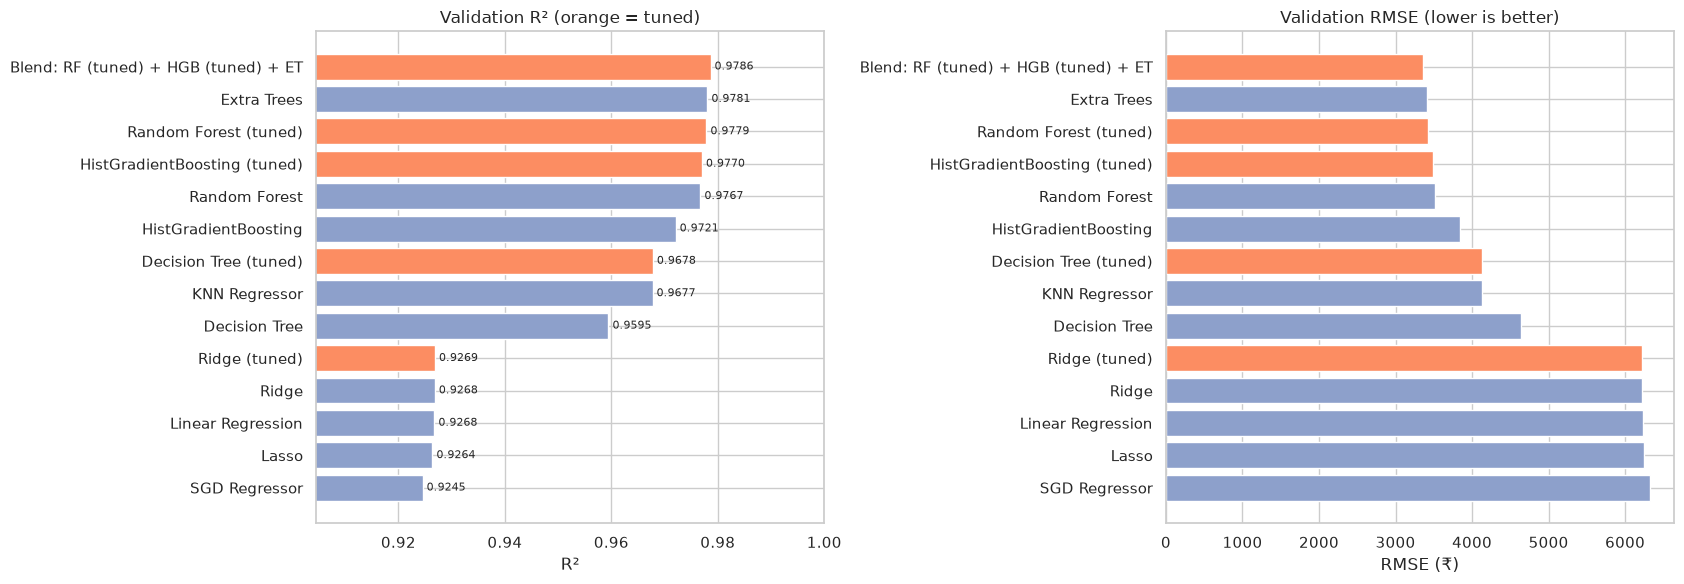

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
colors = res['Stage'].map({'Baseline': '#8da0cb', 'Tuned': '#fc8d62'})
axes[0].barh(res['Model'], res['R2'], color=colors)
axes[0].set_xlim(max(0.0, res['R2'].min() - 0.02), 1.0); axes[0].invert_yaxis()
axes[0].set_title('Validation R² (orange = tuned)'); axes[0].set_xlabel('R²')
for i, v in enumerate(res['R2']):
    axes[0].text(v, i, f' {v:.4f}', va='center', fontsize=8)
axes[1].barh(res['Model'], res['RMSE'], color=colors); axes[1].invert_yaxis()
axes[1].set_title('Validation RMSE (lower is better)'); axes[1].set_xlabel('RMSE (₹)')
plt.tight_layout(); plt.show()

In [36]:
# Baseline vs tuned for the 4 tuned models
pairs = [('Ridge', 'Ridge (tuned)'), ('Decision Tree', 'Decision Tree (tuned)'),
         ('Random Forest', 'Random Forest (tuned)'), ('HistGradientBoosting', 'HistGradientBoosting (tuned)')]
r2 = res.set_index('Model')['R2']
pd.DataFrame([{'Model': b, 'Baseline R2': r2[b], 'Tuned R2': r2[t], 'Gain': r2[t] - r2[b]} for b, t in pairs]).round(4)

,Model,Baseline R2,Tuned R2,Gain
0,Ridge,0.9268,0.9269,0.0000
1,Decision Tree,0.9595,0.9678,0.0083
2,Random Forest,0.9767,0.9779,0.0011
3,HistGradientBoosting,0.9721,0.9770,0.0049


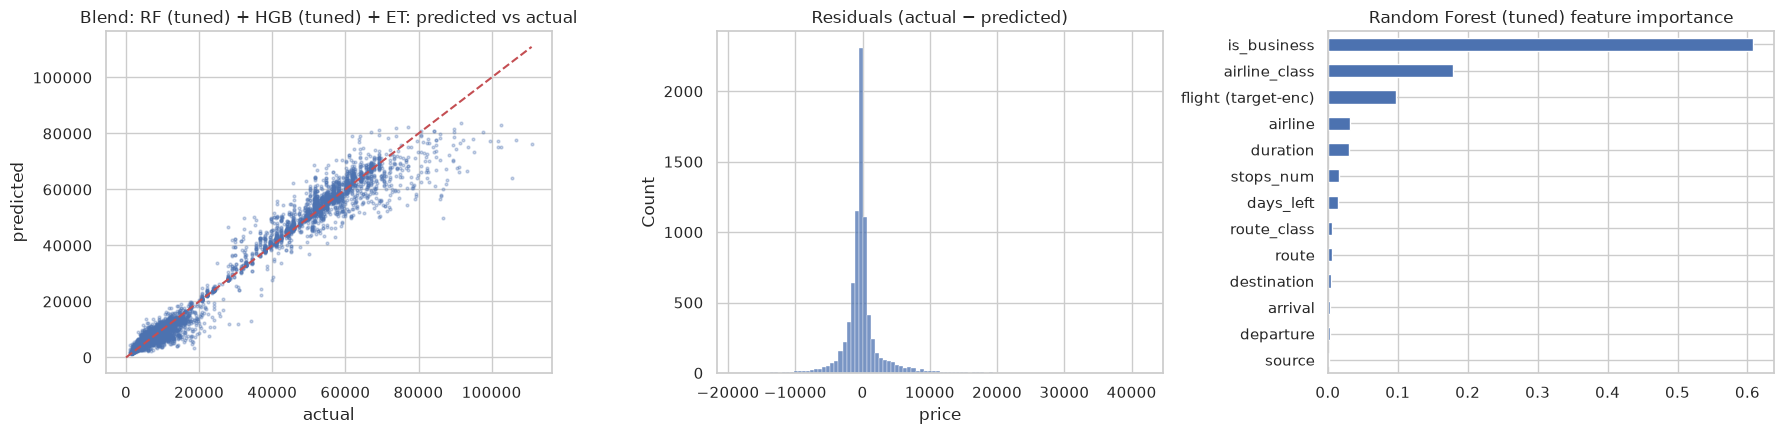

In [37]:
best_name = res.loc[0, 'Model']
best_pred = val_preds[best_name]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].scatter(y_val, best_pred, s=4, alpha=0.3)
lims = [0, y_val.max()]; axes[0].plot(lims, lims, 'r--')
axes[0].set_xlabel('actual'); axes[0].set_ylabel('predicted'); axes[0].set_title(f'{best_name}: predicted vs actual')
resid = y_val - best_pred
sns.histplot(resid, bins=100, ax=axes[1]); axes[1].set_title('Residuals (actual − predicted)')

rf_model = rf_search.best_estimator_.named_steps['model']
imp = pd.Series(rf_model.feature_importances_, index=TREE_FEATURE_NAMES).sort_values()
imp.plot.barh(ax=axes[2]); axes[2].set_title('Random Forest (tuned) feature importance')
plt.tight_layout(); plt.show()

**Comparison summary**

* **Ranking:** tree ensembles (R² ≈ 0.977–0.978) > tuned Decision Tree ≈ KNN (≈ 0.968) > linear models (≈ 0.925–0.927). Price depends non-linearly on `days_left` and on interactions (class × airline × route), and bagging and boosting capture these best.
* **Linear models** (LinearRegression, Ridge, Lasso, SGD) score almost the same. There are far more rows than one-hot columns, so regularization barely matters: Ridge's CV score is flat for α between 0.01 and 10, and tuning gains ≈ 0.0001.
* **Tuning gains:** Decision Tree +0.008 (depth 25 with `min_samples_leaf=10` stops it memorizing single tickets), HistGradientBoosting +0.005 (lower learning rate with more iterations), Random Forest +0.001 (`max_features=0.4` decorrelates the trees).
* **Blending** RF + HGB + Extra Trees gives the best validation score of all, because the three ensembles make partly independent errors.
* **Feature importance:** `is_business` / `airline_class` dominate, followed by `duration`, `days_left` and the target-encoded `flight`. This agrees with the EDA.
* The top model in the comparison table is used for the submission.

## 12. Final model & submission

The best model (top of the comparison table) is **refit on the full de-duplicated training set** with its tuned hyperparameters. It then predicts the test set.

In [38]:
if best_name == blend_name:
    chosen = [fitted[m] for m in blend_members]
else:
    chosen = [fitted[best_name]]
print('Final model:', best_name)

test_preds = []
for est in chosen:
    model = clone(est).fit(X, y)          # refit on all training data
    test_preds.append(model.predict(X_test))
test_pred = np.mean(test_preds, axis=0)
test_pred = np.clip(test_pred, y.min() * 0.9, None)   # guard against impossible (negative/tiny) prices

submission = pd.DataFrame({'id': test_raw['id'], 'price': test_pred})
assert submission.shape == sample_sub.shape and (submission['id'].values == sample_sub['id'].values).all()
submission.to_csv('submission.csv', index=False)
print(submission.shape)
submission.head()

Final model: Blend: RF (tuned) + HGB (tuned) + ET
(10000, 2)


,id,price
0,0,4602.889250
1,1,9027.727147
2,2,5070.194960
3,3,58744.582495
4,4,47772.238236


In [39]:
submission['price'].describe()

count    10000.000000
mean     20858.338490
std      22485.909677
min       1307.352525
25%       5083.658578
50%       7296.864258
75%      44143.790115
max      86231.969879
Name: price, dtype: float64

## Conclusion

* **Data quality fixes:** removed 250 exact duplicates. Recovered every missing `airline` value from the flight-code prefix, and undid the spreadsheet corruption of IndiGo flight codes (`6E-xxx` → `6.00E-xxx`). Imputed `stops`, `departure` and `duration` from rows of the same flight/route, and `days_left` with the median.
* **Key drivers of price:** seat class (≈ 8× gap), airline, how many days are left before the flight (sharp increase in the final ~2 weeks), number of stops, and route.
* **Models:** 9 classical sklearn regressors were trained (Linear, Ridge, Lasso, SGD, KNN, Decision Tree, Random Forest, Extra Trees, HistGradientBoosting), and 4 of them were tuned (Ridge, Decision Tree, Random Forest, HistGradientBoosting). Tree ensembles perform best (validation R² ≈ 0.978). The final submission uses the top-ranked model on the validation set, an average of the tuned Random Forest, the tuned HistGradientBoosting and Extra Trees, refit on all of the training data.